## Numerical solution of ODE

In [42]:
import numpy as np
import matplotlib.pyplot as plt

In [43]:
def ode(t, y):
    return -2 * t * y

def ode_2_der(t, y):
    return (4 * t**2 - 2)* y

def ode_sol(t):
    return np.exp(-t**2)

In [44]:
def euler(tn, yn, h):
    return  yn + h * ode(t=tn, y=yn)


def heun(tn, yn, h):
    k1 = ode(tn, yn)
    k2 = ode(tn + h, yn + h * k1)
    return yn + h/2 * (k1 + k2)

def taylor_second_order(tn, yn, h):
    yp = ode(tn, yn)
    ypp = ode_2_der(tn, yn)
    return yn + h * yp + 0.5 * (h**2) * ypp

### Problem 5 a and b

In [45]:
# Parameters
t0, y0 = 0.0, 1.0
h = 0.1
final = 1.0
n_steps = round((final - t0) / h)

# Reset state
t = t0
y_euler = y0
y_heun = y0
y_taylor = y0

for _ in range(n_steps):
  y_euler = euler(t, y_euler, h)
  y_heun = heun(t, y_heun, h)
  y_taylor = taylor_second_order(t, y_taylor, h)
  t += h

exact = np.exp(-(final**2))

print(f"Euler solution:   {y_euler:.6f}  (Error: {abs(y_euler - exact):.6e})")
print(f"Heun solution:    {y_heun:.6f}  (Error: {abs(y_heun - exact):.6e})")
print(f"Taylor solution:  {y_taylor:.6f}  (Error: {abs(y_taylor - exact):.6e})")
print(f"Exact solution:   {exact:.6f}")

Euler solution:   0.381707  (Error: 1.382724e-02)
Heun solution:    0.369053  (Error: 1.173953e-03)
Taylor solution:  0.365261  (Error: 2.618643e-03)
Exact solution:   0.367879


## Problem 5 d

In [46]:


h_values =[10 ** -2, 10 ** -3, 10 ** -4]


err_euler = []
err_heun = []
err_taylor = []

# h1
for step_h in h_values:
    
    
    t = t0
    y_e = y0
    y_h = y0
    y_t = y0

    max_e = 0.0
    max_h = 0.0
    max_t = 0.0
    
    n_steps = int(round((final - t0) / step_h))
    
    for _ in range(n_steps):
        
        y_e = euler(t, y_e, step_h)
        y_h = heun(t, y_h, step_h)
        y_t = taylor_second_order(t, y_t, step_h)
    
        t += step_h

        y_exact = ode_sol(t)    
        euler_local_error = abs(y_exact - y_e)
        heun_local_error = abs(y_exact - y_h)
        taylor_local_error = abs(y_exact - y_t)
        
        max_e = max(max_e, euler_local_error)
        max_h = max(max_h, heun_local_error )
        max_t = max(max_t, taylor_local_error)
    
    err_euler.append(max_e)
    err_heun.append(max_h)
    err_taylor.append(max_t)
    

p_euler = np.log(err_euler[0] / err_euler[1]) / np.log(10)
p_heun = np.log(err_heun[0] / err_heun[1]) / np.log(10)
p_taylor = np.log(err_taylor[0] / err_taylor[1]) / np.log(10)



print(f"Euler p:   {p_euler:.2f}")
print(f"Heun p:    {p_heun:.2f}  ")
print(f"Taylor p:  {p_taylor:.2f} ")


Euler p:   1.00
Heun p:    2.00  
Taylor p:  2.00 


## Problem 5 e

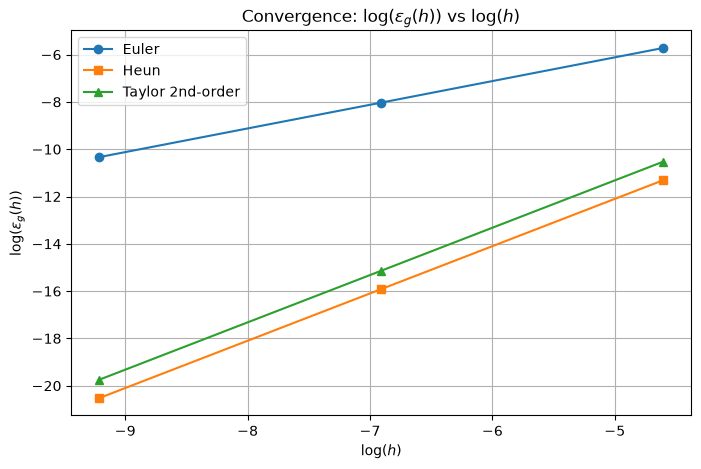

In [47]:
log_h = np.log(h_values)
log_err_euler = np.log(err_euler)
log_err_heun = np.log(err_heun)
log_err_taylor = np.log(err_taylor)

plt.figure(figsize=(8, 5))
plt.plot(log_h, log_err_euler, "o-", label="Euler")
plt.plot(log_h, log_err_heun, "s-", label="Heun")
plt.plot(log_h, log_err_taylor, "^-", label="Taylor 2nd-order")

plt.xlabel(r"$\log(h)$")
plt.ylabel(r"$\log(\epsilon_g(h))$")
plt.title(r"Convergence: $\log(\epsilon_g(h))$ vs $\log(h)$")
plt.grid(True)
plt.legend()
plt.show()